# Hydraulic test-rig data: provenance, stability and features

Helwig, Pignanelli & Schütze (2015), UCI, DOI [10.24432/C5CW21](https://doi.org/10.24432/C5CW21); donated 2018, CC BY 4.0.
2,205 60-second cycles, 43,680 raw values per cycle: 7×6000 + 2×600 + 8×60.
The download is about 73.1 MB compressed; extracted text is substantially larger.

`stable=0` means stable conditions; `stable=1` means static conditions may not yet have been reached. It is diagnostic metadata, never a predictor. Full-dataset descriptive EDA is not an independent test. The protocol is in reports/AUDIT.md.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd() if (Path.cwd() / 'src').is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.data import *
FIG = ROOT / 'reports' / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
profile = load_profile()


,cooler,valve,pump,accumulator,stable
count,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000
mean,41.240816,90.693878,0.669388,107.199546,0.342857
std,42.383143,10.681802,0.817233,16.435848,0.474772
min,3.000000,73.000000,0.000000,90.000000,0.000000
25%,3.000000,80.000000,0.000000,90.000000,0.000000
50%,20.000000,100.000000,0.000000,100.000000,0.000000
75%,100.000000,100.000000,1.000000,130.000000,1.000000
max,100.000000,100.000000,2.000000,130.000000,1.000000


stable
stable                1449
possibly transient     756
Name: count, dtype: int64

stable,0,1
cooler,,
3,480,252
20,480,252
100,489,252


stable,0,1
valve,,
73,360,0
80,360,0
90,360,0
100,369,756


stable,0,1
pump,,
0,489,732
1,480,12
2,480,12


stable,0,1
accumulator,,
90,369,439
100,360,39
115,360,39
130,360,239


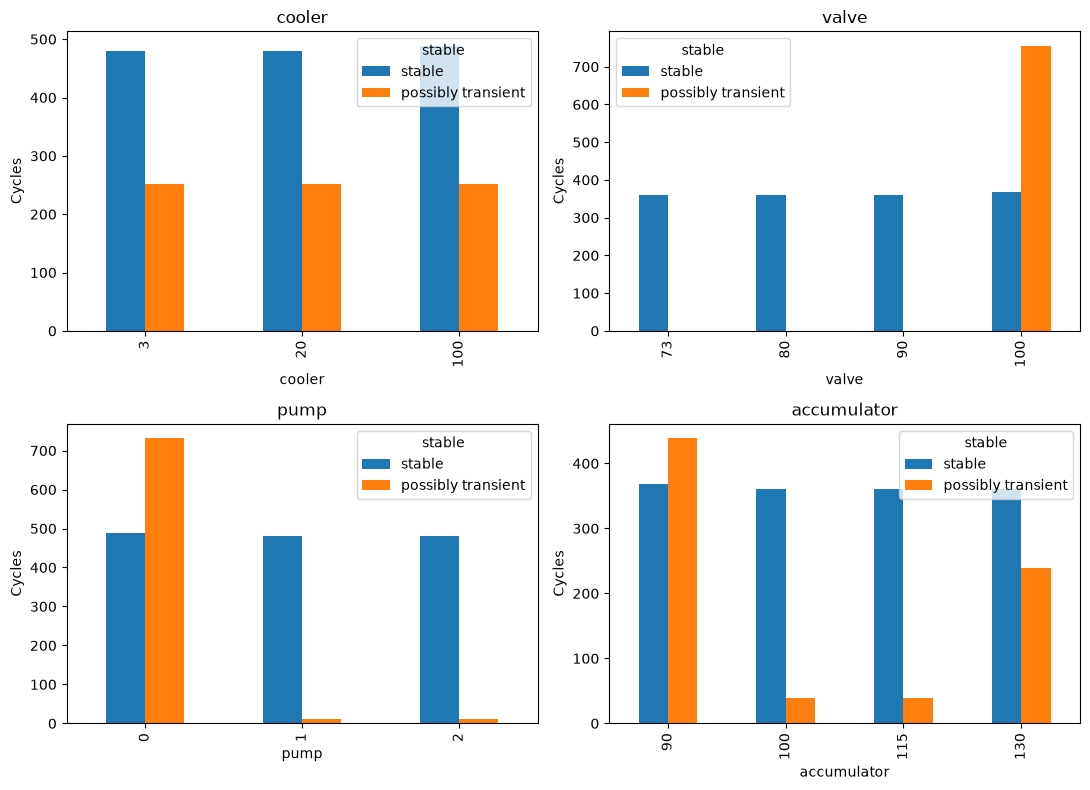

680

In [2]:
assert len(profile) == 2205
assert sum(SAMPLE_RATES.values()) * 60 == 43680
display(profile.describe())
display(profile['stable'].value_counts().rename(index={0: 'stable', 1: 'possibly transient'}))
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
stability = {}
for ax, target in zip(axes.flat, TARGETS):
    table = pd.crosstab(profile[target], profile.stable)
    stability[target] = table.to_dict()
    display(table)
    table.rename(columns={0: 'stable', 1: 'possibly transient'}).plot.bar(ax=ax)
    ax.set_title(target)
    ax.set_ylabel('Cycles')
fig.tight_layout()
fig.savefig(FIG / '01_target_stability.png', dpi=140)
plt.show()
(ROOT / 'reports' / 'stability_counts.json').write_text(json.dumps(stability, indent=2))


## Cycle-local features
187 original statistical descriptors plus 42 FFT descriptors = 229 columns. FFT uses demeaned Hann-window spectra for PS1–PS6 and EPS1 (100 Hz); six summaries per channel. No FFT claim is made for the 1 Hz vibration summary. Energy/RMS² and range/max/min are redundant; correlated inputs complicate importance. No scaling or imputation is learned globally. Files are loaded one sensor at a time; cache is regenerated on each EDA execution.

  CE ...


  CP ...


  EPS1 ...


  FS1 ...


  FS2 ...


...

  TS3 ...


  TS4 ...


  VS1 ...


Feature matrix: (2205, 229)


,CE_mean,CE_std,CE_min,CE_max,CE_median,CE_ptp,CE_rms,CE_crest,CE_skew,CE_kurt,...,VS1_std,VS1_min,VS1_max,VS1_median,VS1_ptp,VS1_rms,VS1_crest,VS1_skew,VS1_kurt,VS1_energy
0,39.601350,6.317224,28.866,47.438,40.6755,18.572,40.102048,1.182932,-0.267015,-1.419685,...,0.026852,0.532,0.624,0.5770,0.092,0.577575,1.080380,-0.044978,-1.275101,0.333592
1,25.786433,1.672019,23.320,29.208,25.3855,5.888,25.840584,1.130315,0.401015,-1.097494,...,0.027013,0.524,0.626,0.5595,0.102,0.566494,1.105042,0.770789,-0.238839,0.320916
2,22.218233,0.633003,21.220,23.554,22.1040,2.334,22.227249,1.059690,0.304239,-1.103712,...,0.036422,0.529,0.662,0.5620,0.133,0.577683,1.145958,0.934103,-0.042351,0.333717
3,20.459817,0.451941,19.673,21.565,20.4805,1.892,20.464808,1.053760,0.183835,-0.251527,...,0.033184,0.527,0.645,0.5550,0.118,0.570233,1.131117,1.007775,-0.165555,0.325166
4,19.787017,0.287728,19.133,20.460,19.7985,1.327,19.789109,1.033902,-0.025580,-0.073937,...,0.033203,0.524,0.660,0.5760,0.136,0.578321,1.141235,0.795914,0.027945,0.334455


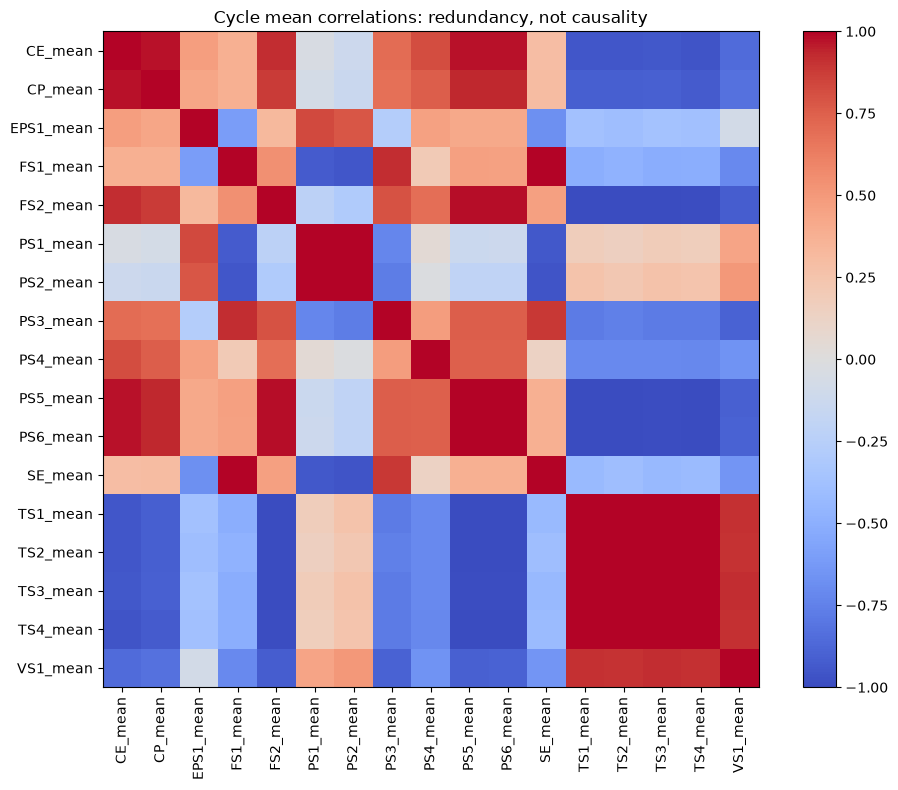

In [3]:
X = build_feature_frame(spectral=True)
assert X.shape == (2205, 229)
assert np.isfinite(X.to_numpy()).all()
X.to_pickle(ROOT / 'data' / 'features.pkl')
print('Feature matrix:', X.shape)
display(X.head())
means = X[[c for c in X if c.endswith('_mean')]]
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(means.corr(), vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(means.columns)), means.columns, rotation=90)
ax.set_yticks(range(len(means.columns)), means.columns)
fig.colorbar(im, ax=ax)
ax.set_title('Cycle mean correlations: redundancy, not causality')
fig.tight_layout()
fig.savefig(FIG / '02_sensor_correlation.png', dpi=140)
plt.show()


Stability and fault labels can be associated, so stable/transient scores must include class support. They cannot establish that transients cause errors. The modeling notebook reports both strata using the same saved final predictions and the full target label set; absent classes receive zero recall and lower fixed-label macro-F1. Regime/sequence dependence remains a limitation of random-cycle evaluation.